# Sketched kernel moment–SoS BLASSO in the plane (§4.4, Figure 4)

Self-contained notebook for the planar run of the **sketched kernel moment–SoS relaxation** (eq:sketch-sdp, §4.2 of the
paper) in §4.4 (`figs/fig_blasso2d_sketch.pdf`). It uses the code of `fig_gmm10.ipynb` (the ten-dimensional showcase of the
Introduction) at $p=2$: sample and sketch, solve eq:sketch-sdp, extract the atoms by flat extension, polish them by Newton
on the three-atom BLASSO and check the dual certificate. It validates Theorem 19 and Corollary 21 on eq:sketch-sdp itself
(the other experiments of §4.4 solve the diagonal relaxation of Remark diagonal).

**Model.** $p=2$, $\Sigma=\sigma^2I$ with $\sigma=0.35$, the configuration of §4.4 rescaled to the unit disc:
$\mu^\star=0.5\,\delta_{(-0.5,-0.5)}+0.3\,\delta_{(0.5,0.5)}+0.2\,\delta_{(0.5,-0.5)}$ (separations $1=2.9\,\sigma$ and
$\sqrt2=4\,\sigma$); $\mathcal X$ the unit disc ($R=1$, ball localiser).

**Sketch.** $n$ i.i.d. samples, $m$ random frequencies uniform on the cube $\|\xi\|_\infty\le1/\tau$ with $1/\tau=\Xi/\sqrt2$,
$\Xi=4.3$ ($\sigma\Xi=1.5$ as in the showcase; $|\xi^\top t_k|\le2.97$ at the centres, $\widehat{G_\Sigma}\ge0.34$ on the band);
$\hat z_\ell=\frac1n\sum_j e^{i\xi_\ell^\top X_j}$.

**Relaxation.** Level $d=0$ ($\theta_0\equiv1$), truncated exponential of degree $r=18$
($\varepsilon_r=(\Xi R)^{19}/19!=8.5\times10^{-6}$), relaxation order $D=9$: $190$ moments, $M_9(y_\pm)$ of size $55\times55$,
ball localisers of size $45\times45$; penalty $\beta/v_\tau=10^{-3}$ at $n=10^6$, scaled as $n^{-1/2}$ in the sample-size
sweep; SCS at tolerance $10^{-10}$ (at most $50\,000$ iterations) through CVXPY; ranks read at the relative tolerance
$10^{-3}$ on the singular values; $100$ multistarts for $\sup_{\mathcal X}\eta$.

**Plan** (46 runs, `blasso2d_sketch_results/<tag>.json`): (1) a sample-size sweep $n\in\{10^3,3\cdot10^3,\dots,10^6\}$ with
three seeds each (`n*_seed*`); (2) a truncation-degree sweep $r\in\{4,6,8,10,12,14,18\}$ at fixed $D=9$ (`r*`); (3) a
sketch-size sweep $m\in\{25,50,100,200,400\}$ with three frequency draws each (`m*_f*`); (4) a band sweep $\Xi\in\{2,3,6\}$
with the least even $r$ giving $\varepsilon_r\le10^{-5}$ ($r=12,16,24$, $D=r/2$; `Xi*`).

**Run time.** All 46 runs took 3 min on one single-threaded process (laptop, Apple silicon): under 1 s per SDP
(2.3 s at $D=12$), about 3 s per run with sampling, polishing and the multistarts, except $r=4$ (about 50 s, SCS stops at
its iteration limit). Set `RECOMPUTE = True` to rerun the plan (runs whose JSON exists are skipped); by default the notebook
only reads the stored results, prints the key numbers and draws the figure.

In [1]:
import os, glob, json, math, time
RECOMPUTE = False                     # True: rerun the 46 programs (about 3 min); False: read blasso2d_sketch_results/*.json only
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[v] = "1"               # one single-threaded process
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

RESDIR = "blasso2d_sketch_results"     # stored results (relative to code/)
FIGDIR = os.path.join("..", "figs")    # the figure of the paper
os.makedirs(RESDIR, exist_ok=True); os.makedirs(FIGDIR, exist_ok=True)
GREY = "#6b6a66"
print("numpy", np.__version__, "| matplotlib", matplotlib.__version__, "| RECOMPUTE =", RECOMPUTE)

numpy 2.3.3 | matplotlib 3.10.6 | RECOMPUTE = False


## Experiment code

Embedded copy of the code of `fig_gmm10.ipynb` (`gmm10_proto.py`) with one added option, `--centres` (explicit centres,
overriding the equilateral triangle): sample and sketch (eq:sketch), build the data matrix of eq:sketch-functional, solve
eq:sketch-sdp with CVXPY, read the ranks of $M_t(y_+^\star)$, Curto–Fialkow extraction, untilt (eq:untilt), Newton polishing of
the $s$-atom BLASSO $\tilde J$ (eq:impl-blasso), dual certificate $\eta$ (Remark blasso-dual) with a multistart search of
$\sup_{\mathcal X}\eta$, and the SoS identity from the SDP duals. `main(argv)` takes the command-line options of the script.

In [2]:
"""Sketched kernel moment-SoS BLASSO (eq:sketch-sdp of kernel_moment_sos.tex) for a Gaussian
mixture in ambient dimension p (=10), n samples, m random frequencies, 3 close spikes.

Pipeline: sample -> sketch z_hat (eq:sketch) -> SDP (eq:sketch-sdp) with CVXPY -> ranks of M_t(y_+)
-> Curto-Fialkow extraction -> untilt -> polishing (Newton on the s-atom BLASSO) -> certificates.

Usage (all parameters are command-line options, see --help):
  python3 gmm10_proto.py --n 1000000 --m 200 --D 3 --r 6 --sep 2.0 --pen 1e-3 --solver CLARABEL --tag run1
Outputs: JSON summary in <outdir>/<tag>.json (+ printed table).  Only writes under --outdir.
"""
import os, sys, math, time, json, argparse, itertools
NTHREADS = os.environ.get("GMM10_THREADS", "1")
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(v, NTHREADS)
import numpy as np
import scipy.sparse as sp
from scipy.optimize import minimize
import resource

# ----------------------------------------------------------------------------- polynomials
def monomials(p, n):
    """Exponents alpha in N^p, |alpha| <= n, graded (degree, then lexicographic) order."""
    out = []
    for k in range(n + 1):
        for c in itertools.combinations_with_replacement(range(p), k):
            a = [0] * p
            for i in c:
                a[i] += 1
            out.append(tuple(a))
    out.sort(key=lambda a: (sum(a), tuple(-ai for ai in a)))
    return out

def theta_poly(p, d, sigma):
    """theta_d(t) = sum_{k<=d} a_k |t|^{2k}, a_k = (2 sigma^2)^{-k}/k!  (Lemma gmm-hierarchy, (W))."""
    T = {tuple([0] * p): 1.0}
    for k in range(1, d + 1):
        ak = (2 * sigma ** 2) ** (-k) / math.factorial(k)
        # |t|^{2k} = sum_{|b|=k} (k!/b!) t^{2b}
        for b in itertools.combinations_with_replacement(range(p), k):
            bb = [0] * p
            for i in b:
                bb[i] += 1
            coef = math.factorial(k) / math.prod(math.factorial(x) for x in bb)
            al = tuple(2 * x for x in bb)
            T[al] = T.get(al, 0.0) + ak * coef
    return T

def multinomial_inv_fact(alpha):
    return 1.0 / math.prod(math.factorial(a) for a in alpha)

# ----------------------------------------------------------------------------- model
def make_centres(p, sep, rng, plane="random"):
    """Equilateral triangle of side `sep`, centred at the origin, in a random 2-plane of R^p."""
    circ = sep / math.sqrt(3.0)
    ang = np.array([0.0, 2 * math.pi / 3, 4 * math.pi / 3]) + 0.3
    pts2 = circ * np.column_stack([np.cos(ang), np.sin(ang)])
    if plane == "coord":
        Q = np.eye(p)[:, :2]
    else:
        Q, _ = np.linalg.qr(rng.standard_normal((p, 2)))
    return pts2 @ Q.T, Q

def sample_and_sketch(T, w, sigma, n, xi, rng, chunk=100_000):
    """X_j ~ sum_k w_k N(t_k, sigma^2 I); z_hat_l = (1/n) sum_j exp(i xi_l^T X_j)  (eq:sketch-a)."""
    p = T.shape[1]; m = xi.shape[0]
    z = np.zeros(m, complex)
    done = 0
    while done < n:
        c = min(chunk, n - done)
        comp = rng.choice(len(w), size=c, p=w)
        X = T[comp] + sigma * rng.standard_normal((c, p))
        z += np.exp(1j * (X @ xi.T)).sum(axis=0)
        done += c
    return z / n

def draw_freqs(m, p, inv_tau, law, rng):
    """Frequencies: 'cube' = uniform on ||xi||_inf <= 1/tau (paper); 'ball' = uniform on ||xi||_2 <= Xi=1/tau."""
    if law == "cube":
        return rng.uniform(-inv_tau, inv_tau, size=(m, p))
    g = rng.standard_normal((m, p)); g /= np.linalg.norm(g, axis=1, keepdims=True)
    rad = inv_tau * rng.uniform(0, 1, size=(m, 1)) ** (1.0 / p)
    return g * rad

# ----------------------------------------------------------------------------- SDP data
def build_data_matrix(xi, Ghat, MON, idx, r, th):
    """Rows A_l = Ghat(xi_l) * coefficients of theta_d * e_r^{(xi_l)}  (eq:sketch-functional), complex (m, N)."""
    m, p = xi.shape
    monr = [a for a in MON if sum(a) <= r]
    E = np.zeros((m, len(monr)), complex)                       # coefficients of e_r^{(xi)}: (i xi)^alpha/alpha!
    for j, a in enumerate(monr):
        E[:, j] = (1j) ** sum(a) * np.prod(xi ** np.array(a), axis=1) * multinomial_inv_fact(a)
    A = np.zeros((m, len(MON)), complex)
    for j, a in enumerate(monr):
        for b, cb in th.items():
            A[:, idx[tuple(x + y for x, y in zip(a, b))]] += cb * E[:, j]
    return Ghat[:, None] * A

def selector(basis, idx, g=None):
    """Sparse T (nb^2, N) with (T y) = vec(M(g y)); g = {alpha: coef} (None -> moment matrix)."""
    nb = len(basis); rows, cols, vals = [], [], []
    g = {tuple([0] * len(basis[0])): 1.0} if g is None else g
    for i, a in enumerate(basis):
        for j, b in enumerate(basis):
            for c, cg in g.items():
                rows.append(i * nb + j); cols.append(idx[tuple(x + y + z for x, y, z in zip(a, b, c))]); vals.append(cg)
    return sp.csr_matrix((vals, (rows, cols)), shape=(nb * nb, len(idx)))

def solve_sdp(A, z, pen, thvec, TM, TL, nbD, nbL, N, solver, eps, max_iters, verbose=False):
    import cvxpy as cp
    yp, ym = cp.Variable(N), cp.Variable(N)
    diff = yp - ym
    Ar, Ai = A.real, A.imag
    m = A.shape[0]
    obj = (cp.sum_squares(z.real - Ar @ diff) + cp.sum_squares(z.imag - Ai @ diff)) / (2 * m) \
        + pen * (thvec @ yp + thvec @ ym)
    Mp = cp.reshape(TM @ yp, (nbD, nbD), order="C"); Mm = cp.reshape(TM @ ym, (nbD, nbD), order="C")
    Lp = cp.reshape(TL @ yp, (nbL, nbL), order="C"); Lm = cp.reshape(TL @ ym, (nbL, nbL), order="C")
    cons = [Mp >> 0, Mm >> 0, Lp >> 0, Lm >> 0]
    prob = cp.Problem(cp.Minimize(obj), cons)
    t0 = time.time()
    kw = {}
    if solver == "SCS":
        kw = dict(eps_abs=eps, eps_rel=eps, max_iters=max_iters, verbose=verbose)
    elif solver == "CLARABEL":
        kw = dict(tol_gap_abs=eps, tol_gap_rel=eps, tol_feas=eps, max_iter=max_iters, verbose=verbose)
    prob.solve(solver=getattr(cp, solver), **kw)
    tsolve = time.time() - t0
    st = prob.solver_stats
    info = dict(status=prob.status, value=float(prob.value) if prob.value is not None else None,
                solve_time=tsolve, solver_time=getattr(st, "solve_time", None), iters=getattr(st, "num_iters", None))
    duals = [c.dual_value for c in cons]
    return yp.value, ym.value, info, duals

# ----------------------------------------------------------------------------- extraction
def moment_matrix(y, basis, idx):
    nb = len(basis); M = np.empty((nb, nb))
    for i, a in enumerate(basis):
        for j, b in enumerate(basis):
            M[i, j] = y[idx[tuple(x + y_ for x, y_ in zip(a, b))]]
    return M

def _rref_pivots(M, tol):
    A = M.copy().astype(float); nrow, ncol = A.shape; piv, row = [], 0
    for col in range(ncol):
        if row >= nrow: break
        pr = row + np.argmax(np.abs(A[row:, col]))
        if abs(A[pr, col]) <= tol: continue
        A[[row, pr]] = A[[pr, row]]; A[row] /= A[row, col]
        for rr in range(nrow):
            if rr != row: A[rr] -= A[rr, col] * A[row]
        piv.append(col); row += 1
    return piv

def extract_atoms(M, basis, D, tol, rng_seed=1):
    """Curto-Fialkow / Henrion-Lasserre extraction from a flat M_D (rank read with relative tol)."""
    p = len(basis[0]); pos = {a: i for i, a in enumerate(basis)}; deg = [sum(a) for a in basis]
    s = np.linalg.svd(M, compute_uv=False); rank = int(np.sum(s > tol * s[0]))
    piv = [q for q in _rref_pivots(M, tol * s[0]) if deg[q] <= D - 1]
    piv = sorted(piv, key=lambda i: (deg[i], i))
    if len(piv) < rank:
        raise RuntimeError(f"not flat: rank {rank}, {len(piv)} low-degree pivots")
    pivots = piv[:rank]; B = [basis[i] for i in pivots]; Mpp = M[np.ix_(pivots, pivots)]
    mult = []
    for k in range(p):
        Nk = np.zeros((rank, rank))
        for j, b in enumerate(B):
            sh = tuple(b[i] + (1 if i == k else 0) for i in range(p)); si = pos[sh]
            Nk[:, j] = np.linalg.solve(Mpp, M[pivots, si])
        mult.append(Nk)
    g = np.random.default_rng(rng_seed).standard_normal(p)
    _, V = np.linalg.eig(sum(gi * Ni for gi, Ni in zip(g, mult))); Vi = np.linalg.inv(V)
    coords = np.column_stack([np.real(np.diag(Vi @ Nk @ V)) for Nk in mult])
    Phi = np.array([[np.prod(x ** np.array(b)) for x in coords] for b in B], float)
    w, *_ = np.linalg.lstsq(Phi, M[pivots, pos[tuple([0] * p)]], rcond=None)
    return coords, w, rank, s

# ----------------------------------------------------------------------------- objective & polishing
def e_r(xi, T, r):
    """Truncated exponential e_r^{(xi)}(t) = sum_{j<=r} (i xi^T t)^j/j!, shape (m, s); r=None -> exact exp."""
    u = 1j * (xi @ T.T)
    if r is None:
        return np.exp(u)
    out = np.ones_like(u); term = np.ones_like(u)
    for j in range(1, r + 1):
        term = term * u / j; out = out + term
    return out

def e_r_prime(xi, T, r):
    """d/du e_r(u) = e_{r-1}(u) (same shape); r=None -> exp."""
    return e_r(xi, T, None if r is None else r - 1)

def J_atomic(a, T, xi, Ghat, z, pen, r, th=None):
    """J~(mu) of eq:impl-blasso (divided by v_tau, i.e. in the units of eq:sketch-sdp): data/(2m) + pen*sum|a|."""
    m = len(z)
    res = z - Ghat * (e_r(xi, T, r) @ a)
    return float(np.sum(np.abs(res) ** 2) / (2 * m) + pen * np.sum(np.abs(a))), res

def grad_J(theta, s, p, xi, Ghat, z, pen, r):
    a = theta[:s]; T = theta[s:].reshape(s, p); m = len(z)
    E = e_r(xi, T, r); Ep = e_r_prime(xi, T, r)
    res = z - Ghat * (E @ a)                                   # (m,)
    val = np.sum(np.abs(res) ** 2) / (2 * m) + pen * np.sum(np.abs(a))
    ga = -np.real(np.conj(res) @ (Ghat[:, None] * E)) / m + pen * np.sign(a)
    # d res_l / d T_k = -Ghat_l a_k Ep_lk (i xi_l)
    gT = np.empty((s, p))
    for k in range(s):
        gT[k] = -np.real(np.conj(res) * Ghat * a[k] * Ep[:, k] * 1j) @ xi / m
    return val, np.concatenate([ga, gT.ravel()])

def polish(a0, T0, xi, Ghat, z, pen, r, iters=50):
    """Newton (finite-difference Hessian of the analytic gradient) on the s-atom BLASSO; returns a, T, grad norm."""
    s, p = T0.shape
    th = np.concatenate([a0, T0.ravel()])
    f = lambda t: grad_J(t, s, p, xi, Ghat, z, pen, r)
    res = minimize(f, th, jac=True, method="L-BFGS-B", options=dict(maxiter=2000, ftol=1e-16, gtol=1e-12))
    th = res.x
    n = len(th); hist = []
    for it in range(iters):
        v, g = f(th)
        hist.append(np.linalg.norm(g))
        if hist[-1] < 1e-15: break
        H = np.empty((n, n)); h = 1e-6
        for i in range(n):
            e = np.zeros(n); e[i] = h
            H[:, i] = (f(th + e)[1] - f(th - e)[1]) / (2 * h)
        H = 0.5 * (H + H.T)
        try:
            step = np.linalg.solve(H, g)
        except np.linalg.LinAlgError:
            break
        # backtracking on the objective
        lam = 1.0
        for _ in range(30):
            v2, _ = f(th - lam * step)
            if v2 <= v: break
            lam *= 0.5
        th = th - lam * step
    v, g = f(th)
    return th[:s], th[s:].reshape(s, p), float(np.linalg.norm(g)), hist

def eta_fun(t, xi, Ghat, u, pen, r, m):
    """Dual certificate eta(t) = (1/pen) Re[(1/m) sum_l conj(u_l) Ghat_l e_r^{(xi_l)}(t)]  (Remark blasso-dual, theta_0=1)."""
    E = e_r(xi, np.atleast_2d(t), r)                                # (m, nt)
    return np.real((np.conj(u) * Ghat) @ E) / (m * pen)

def sup_eta(xi, Ghat, u, pen, r, R, p, T_hat, rng, nstart=200):
    """Heuristic sup of eta over the ball |t|<=R: multistart projected L-BFGS from random points and the atoms."""
    m = len(u)
    def negeta(t):
        tt = t.reshape(1, p); E = e_r(xi, tt, r)[:, 0]; Ep = e_r_prime(xi, tt, r)[:, 0]
        val = np.real((np.conj(u) * Ghat) @ E) / (m * pen)
        g = np.real((np.conj(u) * Ghat * Ep * 1j) @ xi) / (m * pen)
        return -val, -g
    best = -np.inf; argbest = None; vals = []
    starts = [T_hat[k] for k in range(len(T_hat))]
    for _ in range(nstart):
        d = rng.standard_normal(p); d /= np.linalg.norm(d)
        starts.append(d * R * rng.uniform(0, 1) ** (1 / p))
    for t0 in starts:
        res = minimize(negeta, t0, jac=True, method="L-BFGS-B",
                       bounds=[(-R, R)] * p, options=dict(maxiter=500, gtol=1e-12))
        t = res.x
        if np.linalg.norm(t) > R:
            t = t / np.linalg.norm(t) * R
            v = -negeta(t)[0]
        else:
            v = -res.fun
        vals.append(v)
        if v > best: best, argbest = v, t
    return best, argbest, np.array(vals)

# ----------------------------------------------------------------------------- main
def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--p", type=int, default=10)
    ap.add_argument("--n", type=int, default=1_000_000)
    ap.add_argument("--m", type=int, default=200)
    ap.add_argument("--sigma", type=float, default=1.0, help="component std (units)")
    ap.add_argument("--sep", type=float, default=2.0, help="side of the equilateral triangle of centres")
    ap.add_argument("--weights", type=str, default="0.4,0.35,0.25")
    ap.add_argument("--R", type=float, default=2.0, help="ball radius of X (centres have norm sep/sqrt3)")
    ap.add_argument("--Xi", type=float, default=1.0, help="max frequency norm: cube law -> 1/tau = Xi/sqrt(p); ball law -> radius Xi")
    ap.add_argument("--law", type=str, default="cube", choices=["cube", "ball"])
    ap.add_argument("--r", type=int, default=6)
    ap.add_argument("--d", type=int, default=0)
    ap.add_argument("--D", type=int, default=3)
    ap.add_argument("--pen", type=float, default=1e-3, help="beta/v_tau in eq:sketch-sdp")
    ap.add_argument("--solver", type=str, default="CLARABEL")
    ap.add_argument("--eps", type=float, default=1e-9)
    ap.add_argument("--max_iters", type=int, default=200)
    ap.add_argument("--rank_tol", type=float, default=1e-3)
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--seed_freq", type=int, default=1)
    ap.add_argument("--plane", type=str, default="random", choices=["random", "coord"])
    ap.add_argument("--nstart_eta", type=int, default=100)
    ap.add_argument("--outdir", type=str, default="gmm10_results")
    ap.add_argument("--tag", type=str, default="run")
    ap.add_argument("--verbose", action="store_true")
    ap.add_argument("--centres", type=str, default="", help="explicit centres 'x1,y1;x2,y2;...' (overrides --sep/--plane)")
    args = ap.parse_args(argv)
    os.makedirs(args.outdir, exist_ok=True)
    t_all = time.time()
    p, n, m, sigma, r, d, D, R = args.p, args.n, args.m, args.sigma, args.r, args.d, args.D, args.R
    assert D >= math.ceil((2 * d + r) / 2), "need D >= ceil((2d+r)/2)"
    w = np.array([float(x) for x in args.weights.split(",")]); w /= w.sum()
    rng = np.random.default_rng(args.seed)
    T_true, Q = make_centres(p, args.sep, rng, args.plane)
    if args.centres:
        T_true = np.array([[float(v) for v in c.split(",")] for c in args.centres.split(";")]); assert T_true.shape[1] == p
    out = dict(args=vars(args), sep=args.sep, true_T=T_true.tolist(), true_w=w.tolist())

    # --- frequencies and sketch
    inv_tau = args.Xi / math.sqrt(p) if args.law == "cube" else args.Xi
    xi = draw_freqs(m, p, inv_tau, args.law, np.random.default_rng(args.seed_freq))
    Ghat = np.exp(-0.5 * sigma ** 2 * np.sum(xi ** 2, axis=1))
    t0 = time.time()
    z = sample_and_sketch(T_true, w, sigma, n, xi, rng)
    t_sketch = time.time() - t0
    z_pop = Ghat * (np.exp(1j * (xi @ T_true.T)) @ w)                       # E z_hat = F_sketch mu*
    z_r = Ghat * (e_r(xi, T_true, r) @ w)                                    # F_r mu*
    out["sketch"] = dict(time=t_sketch, noise_linf=float(np.max(np.abs(z - z_pop))),
                         noise_rms=float(np.sqrt(np.mean(np.abs(z - z_pop) ** 2))),
                         trunc_linf=float(np.max(np.abs(z_pop - z_r))), trunc_rms=float(np.sqrt(np.mean(np.abs(z_pop - z_r) ** 2))),
                         Ghat_min=float(Ghat.min()), xi_norm_max=float(np.linalg.norm(xi, axis=1).max()),
                         xiT_max=float(np.abs(xi @ T_true.T).max()), inv_tau=inv_tau,
                         v_tau=float((math.pi / inv_tau) ** (-p)) if args.law == "cube" else None)   # v_tau=(pi tau)^{-p}
    print(f"[sketch] n={n} m={m} time {t_sketch:.1f}s | noise linf {out['sketch']['noise_linf']:.2e} rms {out['sketch']['noise_rms']:.2e}"
          f" | trunc(r={r}) linf {out['sketch']['trunc_linf']:.2e} rms {out['sketch']['trunc_rms']:.2e} | Ghat min {Ghat.min():.3f}"
          f" | max|xi^T t_k| {out['sketch']['xiT_max']:.2f}")

    # --- SDP
    MON = monomials(p, 2 * D); idx = {a: i for i, a in enumerate(MON)}; N = len(MON)
    basisD, basisL = monomials(p, D), monomials(p, D - 1)
    th = theta_poly(p, d, sigma)
    thvec = np.zeros(N)
    for a, c in th.items(): thvec[idx[a]] = c
    t0 = time.time()
    A = build_data_matrix(xi, Ghat, MON, idx, r, th)
    ball = {tuple([0] * p): R ** 2}
    for k in range(p):
        ball[tuple(2 if i == k else 0 for i in range(p))] = -1.0
    TM = selector(basisD, idx); TL = selector(basisL, idx, ball)
    t_build = time.time() - t0
    print(f"[sdp] p={p} D={D} r={r} d={d}: N={N} moments, M_D {len(basisD)}x{len(basisD)}, M_{D-1}(g) {len(basisL)}x{len(basisL)}, build {t_build:.1f}s")
    yp, ym, info, duals = solve_sdp(A, z, args.pen, thvec, TM, TL, len(basisD), len(basisL), N, args.solver, args.eps, args.max_iters, args.verbose)
    mem = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9
    print(f"[sdp] {args.solver} status={info['status']} value={info['value']!r} iters={info['iters']} time {info['solve_time']:.1f}s (solver {info['solver_time']}) | maxrss {mem:.2f} GB")
    out["sdp"] = dict(info, maxrss_GB=mem, build_time=t_build, N=N, nbD=len(basisD), nbL=len(basisL))
    if yp is None:
        json.dump(out, open(os.path.join(args.outdir, args.tag + ".json"), "w"), indent=1); return

    # --- ranks / flat truncation
    svs = {}
    for t in range(D + 1):
        bt = monomials(p, t); Mt = moment_matrix(yp, bt, idx)
        s = np.linalg.svd(Mt, compute_uv=False); svs[t] = (s / s[0]).tolist()
    ranks = {t: int(np.sum(np.array(svs[t]) > args.rank_tol)) for t in svs}
    mass_p, mass_m = float(thvec @ yp), float(thvec @ ym)
    print(f"[rank] masses L(theta): + {mass_p:.6f}, - {mass_m:.2e} | ranks M_t(y+) (tol {args.rank_tol}): {ranks}")
    for t in svs:
        print(f"       sv M_{t}: " + " ".join(f"{v:.1e}" for v in svs[t][:8]))
    out["ranks"] = ranks; out["svals"] = svs; out["mass"] = [mass_p, mass_m]

    MD = moment_matrix(yp, basisD, idx)
    try:
        X_ext, w_ext, rank, _ = extract_atoms(MD, basisD, D, args.rank_tol)
        th_at = np.array([sum(c * np.prod(x ** np.array(a)) for a, c in th.items()) for x in X_ext])
        w_ext = w_ext * th_at                                             # untilt (eq:untilt)
        keep = w_ext > 1e-6
        X_ext, w_ext = X_ext[keep], w_ext[keep]
    except Exception as e:
        print("[extract] failed:", e); X_ext, w_ext = np.zeros((0, p)), np.zeros(0)
    # match to the truth
    def match(Xh, wh):
        if len(Xh) == 0: return None
        errs = []
        for k in range(len(T_true)):
            j = int(np.argmin(np.linalg.norm(Xh - T_true[k], axis=1)))
            errs.append((float(np.linalg.norm(Xh[j] - T_true[k])), float(abs(wh[j] - w[k]))))
        return dict(pos_err=[e[0] for e in errs], w_err=[e[1] for e in errs],
                    pos_err_max=max(e[0] for e in errs), w_err_max=max(e[1] for e in errs))
    out["extract"] = dict(n_atoms=int(len(w_ext)), X=X_ext.tolist(), w=w_ext.tolist(), match=match(X_ext, w_ext))
    print(f"[extract] {len(w_ext)} atoms, weights {np.round(w_ext, 5)}; match {out['extract']['match']}")

    # --- objective values: SDP value vs atomic objectives
    Jx, _ = J_atomic(w_ext, X_ext, xi, Ghat, z, args.pen, r) if len(w_ext) else (np.nan, None)
    Jt_r, _ = J_atomic(w, T_true, xi, Ghat, z, args.pen, r)
    out["values"] = dict(rho_sdp=info["value"], J_extracted=Jx, J_truth_r=Jt_r)
    print(f"[value] rho (SDP) = {info['value']:.12e} | J~(extracted) = {Jx:.12e} | J~(truth) = {Jt_r:.12e}")

    # --- polishing (Newton on the s-atom BLASSO with F_r, then with the exact F_sketch)
    if len(w_ext):
        t0 = time.time()
        a_pol, T_pol, gn, hist = polish(w_ext, X_ext, xi, Ghat, z, args.pen, r)
        Jp, u = J_atomic(a_pol, T_pol, xi, Ghat, z, args.pen, r)
        t_pol = time.time() - t0
        out["polish"] = dict(a=a_pol.tolist(), T=T_pol.tolist(), grad_norm=gn, J=Jp, time=t_pol, newton_hist=hist,
                             match=match(T_pol, a_pol), move_pos=float(np.max(np.linalg.norm(T_pol - X_ext, axis=1))),
                             move_w=float(np.max(np.abs(a_pol - w_ext))))
        gap_rel = (Jx - Jp) / Jp; gap_sdp = (Jp - info["value"]) / Jp
        out["values"].update(J_polished=Jp, gap_extracted_vs_polished_rel=gap_rel, gap_polished_vs_rho_rel=gap_sdp)
        print(f"[polish] |grad| {gn:.1e} after {len(hist)} Newton its ({t_pol:.1f}s); J~(polished) = {Jp:.15e}; "
              f"moved pos {out['polish']['move_pos']:.1e}, w {out['polish']['move_w']:.1e}; match {out['polish']['match']}")
        print(f"[gap] (J~ext - J~pol)/J~pol = {gap_rel:.2e} ; (J~pol - rho)/J~pol = {gap_sdp:.2e}")
        # exact-exponential (untruncated) sketched BLASSO polished from the same start
        a_e, T_e, gn_e, _ = polish(a_pol, T_pol, xi, Ghat, z, args.pen, None)
        Je, _ = J_atomic(a_e, T_e, xi, Ghat, z, args.pen, None)
        out["polish_exact"] = dict(a=a_e.tolist(), T=T_e.tolist(), grad_norm=gn_e, J=Je, match=match(T_e, a_e))
        print(f"[polish exact exp] J = {Je:.12e} |grad| {gn_e:.1e}; match {out['polish_exact']['match']}")
        # --- certificate eta from the polished residual
        eta_at = eta_fun(T_pol, xi, Ghat, u, args.pen, r, m)
        sup_v, sup_t, vals = sup_eta(xi, Ghat, u, args.pen, r, R, p, T_pol, np.random.default_rng(7), args.nstart_eta)
        out["certificate"] = dict(eta_at_atoms=eta_at.tolist(), sup_eta_multistart=float(sup_v),
                                  sup_minus_one=float(sup_v - 1), n_local_max_above_1=int(np.sum(vals > 1 + 1e-9)),
                                  certified_rel_gap=float(max(sup_v - 1, 0.0)))
        print(f"[cert] eta at polished atoms: {eta_at}; multistart sup_X eta = {sup_v:.12f} (sup-1 = {sup_v-1:.2e})")
        # --- SoS certificate from the SDP duals: pen*theta - eta_sdp = v^T Z0 v + g v^T Z1 v + residual
        try:
            Z0, Z1 = duals[0], duals[2]
            Z0 = 0.5 * (Z0 + Z0.T); Z1 = 0.5 * (Z1 + Z1.T)
            u_sdp = z - A @ (yp - ym)
            eta_c = np.real(np.conj(u_sdp) @ A) / m                         # coefficients of eta* (times pen... see Remark)
            lhs = args.pen * thvec - eta_c
            rhs = TM.T @ Z0.ravel() + TL.T @ Z1.ravel()
            res_c = lhs - rhs
            degs = np.array([sum(a) for a in MON])
            res_bound = float(np.sum(np.abs(res_c) * R ** degs))
            eig0 = np.linalg.eigvalsh(Z0).min(); eig1 = np.linalg.eigvalsh(Z1).min()
            out["sos"] = dict(residual_coeff_linf=float(np.abs(res_c).max()), residual_sup_bound=res_bound,
                              Z0_min_eig=float(eig0), Z1_min_eig=float(eig1),
                              certified_min_of_pen_minus_eta_over_X=float(-res_bound + min(0, eig0) * 0 ),
                              rel_to_pen=res_bound / args.pen)
            print(f"[sos] identity residual: coeff linf {np.abs(res_c).max():.1e}, sup bound {res_bound:.1e} (= {res_bound/args.pen:.1e} x pen); "
                  f"min eig Z0 {eig0:.1e}, Z1 {eig1:.1e}")
        except Exception as e:
            print("[sos] unavailable:", e)
    out["total_time"] = time.time() - t_all
    print(f"[done] total {out['total_time']:.1f}s")
    json.dump(out, open(os.path.join(args.outdir, args.tag + ".json"), "w"), indent=1, default=float)

## The plan

The 46 configurations (base configuration above). With `RECOMPUTE = True` each missing run is solved and written to
`blasso2d_sketch_results/<tag>.json`; otherwise nothing is solved.

In [3]:
BASE = dict(p=2, sigma=0.35, R=1.0, Xi=4.3, law="cube", d=0, weights="0.5,0.3,0.2", centres="-0.5,-0.5;0.5,0.5;0.5,-0.5",
            solver="SCS", eps="1e-10", max_iters=50000, rank_tol="1e-3", nstart_eta=100, r=18, D=9, m=200, n=1_000_000,
            pen="1e-3", seed=0, seed_freq=100)
SEEDS = [0, 1, 2]        # sample seeds (frequency seed = 100 + seed)
NS = [1_000, 3_000, 10_000, 30_000, 100_000, 300_000, 1_000_000]
RS = [4, 6, 8, 10, 12, 14, 18]
MS = [25, 50, 100, 200, 400]
XIS = {2.0: 12, 3.0: 16, 6.0: 24}   # band -> least even r with (Xi R)^{r+1}/(r+1)! <= 1e-5
PLAN = []
for n in NS:                                                      # (1) sample-size sweep, pen proportional to n^{-1/2}
    for s in SEEDS:
        PLAN.append(dict(tag=f"n{n}_seed{s}", n=n, seed=s, seed_freq=100 + s, pen=f"{1e-3*(1e6/n)**0.5:.4e}"))
for r in RS:                                                      # (2) truncation degree at fixed D = 9
    PLAN.append(dict(tag=f"r{r}", r=r))
for m in MS:                                                      # (3) sketch size, three frequency draws
    for fs in (101, 102, 103):
        PLAN.append(dict(tag=f"m{m}_f{fs}", m=m, seed_freq=fs))
for Xi, r in XIS.items():                                         # (4) band, r adjusted to eps_r <= 1e-5
    PLAN.append(dict(tag=f"Xi{Xi}", Xi=Xi, r=r, D=r // 2))
print(len(PLAN), "configurations")

if RECOMPUTE:
    t0 = time.time()
    for cfg in PLAN:
        if os.path.exists(os.path.join(RESDIR, cfg["tag"] + ".json")):
            print("skip", cfg["tag"]); continue
        argv = []
        for k, v in {**BASE, **{k: v for k, v in cfg.items() if k != "tag"}}.items():
            argv += [f"--{k}={v}"]
        argv += ["--tag", cfg["tag"], "--outdir", RESDIR]
        print("=== ", cfg["tag"], flush=True); main(argv)
    print(f"all runs done in {(time.time()-t0)/60:.1f} min")
else:
    print("RECOMPUTE = False: reading the stored results in", RESDIR)

46 configurations
RECOMPUTE = False: reading the stored results in blasso2d_sketch_results


## Key numbers

Status, rank of $M_D(y_+^\star)$ and fourth-to-first singular-value ratio, number of extracted atoms, maximum position and
weight errors (matching each true centre to its nearest atom), the relative objective gap between the extracted and the
Newton-polished atoms $(\tilde J_{\rm ext}-\tilde J_{\rm pol})/\tilde J_{\rm pol}$, the multistart $\sup_{\mathcal X}\eta-1$,
and, for the sketch, the truncation error $\max_\ell|(F-F_r)\mu^\star|_\ell$ and the sampling deviation
$\max_\ell|\hat z_\ell-\mathbb E\hat z_\ell|$ ($\gamma_n$ of eq:concentration-a).

In [4]:
RUNS = {os.path.basename(f)[:-5]: json.load(open(f)) for f in sorted(glob.glob(os.path.join(RESDIR, "*.json")))}
print(len(RUNS), "runs; SCS statuses:", {t: o["sdp"]["status"] for t, o in RUNS.items() if o["sdp"]["status"] != "optimal"} or "all optimal",
      "; max solve time %.1f s; max RSS %.2f GB" % (max(o["sdp"]["solve_time"] for o in RUNS.values()), max(o["sdp"]["maxrss_GB"] for o in RUNS.values())))

def row(tag):
    o = RUNS[tag]; a = o["args"]; D = str(a["D"]); e = o["extract"]; v = o["values"]; c = o.get("certificate"); k = o["sketch"]
    s = (f"{tag:15s} n={a['n']:>8d} m={a['m']:>3d} r={a['r']:>2d} D={a['D']:>2d} Xi={a['Xi']:.1f} | {o['sdp']['status']:18s} | rank {o['ranks'][D]} "
         f"s4/s1 {o['svals'][D][3]:.1e} | atoms {e['n_atoms']} ")
    if c and e["match"] and e["n_atoms"] >= 3:
        s += (f"pos {e['match']['pos_err_max']:.4f} w {e['match']['w_err_max']:.4f} | gap ext/pol {v['gap_extracted_vs_polished_rel']:8.1e} "
              f"sup eta-1 {c['sup_minus_one']:8.1e} ")
    return s + f"| trunc {k['trunc_linf']:.1e} noise {k['noise_linf']:.1e}"

print("\n--- sample-size sweep (m = 200, r = 18, pen = 1e-3 (1e6/n)^{1/2})")
for n in NS:
    for s in SEEDS: print(row(f"n{n}_seed{s}"))
print("\n--- truncation degree (n = 1e6, m = 200, D = 9)")
for r in RS: print(row(f"r{r}"))
print("\n--- sketch size (n = 1e6, r = 18, three frequency draws)")
for m in MS:
    for fs in (101, 102, 103): print(row(f"m{m}_f{fs}"))
print("\n--- band (n = 1e6, m = 200, eps_r <= 1e-5)")
for Xi in XIS: print(row(f"Xi{Xi}"))

# aggregates quoted in the paper
nrun = [RUNS[f"n{n}_seed{s}"] for n in NS for s in SEEDS]
print("\nSample-size sweep (21 runs): ranks", sorted({o["ranks"]["9"] for o in nrun}), "; atoms", sorted({o["extract"]["n_atoms"] for o in nrun}),
      "; max s4/s1 %.1e ; gap ext/pol <= %.1e ; |sup eta - 1| <= %.1e" % (
      max(o["svals"]["9"][3] for o in nrun), max(o["values"]["gap_extracted_vs_polished_rel"] for o in nrun),
      max(abs(o["certificate"]["sup_minus_one"]) for o in nrun)))
pe = {n: np.mean([RUNS[f"n{n}_seed{s}"]["extract"]["match"]["pos_err_max"] for s in SEEDS]) for n in NS}
slope = np.polyfit(np.log(NS), np.log([pe[n] for n in NS]), 1)[0]
print("  mean max position error:", ", ".join(f"n={n:.0e} {pe[n]:.4f}" for n in NS), "; log-log slope %.2f (n^{-1/2}: -0.50)" % slope)
mrun = [RUNS[f"m{m}_f{fs}"] for m in MS for fs in (101, 102, 103)]
print("Sketch-size sweep (15 runs): ranks", sorted({o["ranks"]["9"] for o in mrun}), "; max position error in [%.4f, %.4f]" % (
      min(o["extract"]["match"]["pos_err_max"] for o in mrun), max(o["extract"]["match"]["pos_err_max"] for o in mrun)))
print("Truncation degree:", "; ".join(f"r={r}: rank {RUNS[f'r{r}']['ranks']['9']}, {RUNS[f'r{r}']['extract']['n_atoms']} atoms, trunc {RUNS[f'r{r}']['sketch']['trunc_linf']:.1e}" for r in RS))
print("Band:", "; ".join(f"Xi={Xi}: rank {RUNS[f'Xi{Xi}']['ranks'][str(r // 2)]}, pos {RUNS[f'Xi{Xi}']['extract']['match']['pos_err_max']:.4f}" for Xi, r in XIS.items()))

46 runs; SCS statuses: {'r4': 'optimal_inaccurate'} ; max solve time 46.4 s; max RSS 2.25 GB

--- sample-size sweep (m = 200, r = 18, pen = 1e-3 (1e6/n)^{1/2})
n1000_seed0     n=    1000 m=200 r=18 D= 9 Xi=4.3 | optimal            | rank 3 s4/s1 1.6e-11 | atoms 3 pos 0.1833 w 0.0895 | gap ext/pol  0.0e+00 sup eta-1  8.9e-16 | trunc 6.1e-10 noise 4.6e-02
n1000_seed1     n=    1000 m=200 r=18 D= 9 Xi=4.3 | optimal            | rank 3 s4/s1 1.6e-11 | atoms 3 pos 0.1357 w 0.0666 | gap ext/pol  1.2e-16 sup eta-1  2.2e-16 | trunc 5.1e-10 noise 2.7e-02
n1000_seed2     n=    1000 m=200 r=18 D= 9 Xi=4.3 | optimal            | rank 3 s4/s1 9.7e-12 | atoms 3 pos 0.2050 w 0.0856 | gap ext/pol  0.0e+00 sup eta-1  1.1e-15 | trunc 3.7e-10 noise 4.2e-02
n3000_seed0     n=    3000 m=200 r=18 D= 9 Xi=4.3 | optimal            | rank 3 s4/s1 2.7e-11 | atoms 3 pos 0.0807 w 0.0589 | gap ext/pol  0.0e+00 sup eta-1  1.1e-15 | trunc 6.1e-10 noise 3.6e-02
n3000_seed1     n=    3000 m=200 r=18 D= 9 Xi=4.3 | opti

## The figure of the paper (`../figs/fig_blasso2d_sketch.pdf`)

No titles: the panels are described in the caption. *(a)* True centres (circles, area proportional to the weight; dotted: one
standard deviation; grey: the unit disc $\mathcal X$) and extracted atoms (crosses), $n=10^6$, $m=200$, seed 0.
*(b)* Normalised singular values of $M_9(y_+^\star)$ at $n=10^6$, $m=200$ for the degrees $r=4,6,8,12,18$ (colours), and for the
fifteen runs of the sketch-size sweep $m=25$ to $400$ at $r=18$ (grey, "$m$ sweep"); dashed: the rank tolerance. *(c)* Against $n$, three
seeds: the maximum position error of the extracted atoms, dashed: $n^{-1/2}$ through the mean at $n=10^6$; the relative
objective gap between the extracted and the polished atoms (exact zeros drawn hollow on the floor $10^{-17}$) and
$|\sup_{\mathcal X}\eta-1|$; grey: below the machine epsilon.

saved ../figs/fig_blasso2d_sketch.pdf


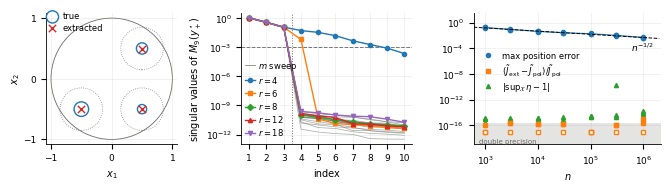

In [5]:
def paper_fig(path):
    rc = {"font.size": 7, "axes.labelsize": 7, "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6,
          "lines.linewidth": 1.0, "lines.markersize": 3, "axes.linewidth": 0.6, "axes.spines.top": False,
          "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
          "legend.handlelength": 1.8, "legend.borderpad": 0.3, "legend.labelspacing": 0.25, "legend.frameon": False}
    FLOOR, EPS = 1e-17, np.finfo(float).eps
    with plt.rc_context(rc):
        fig, axs = plt.subplots(1, 3, figsize=(6.6, 1.75), gridspec_kw=dict(width_ratios=[0.8, 1.0, 1.1]))
        # (a) the plane
        ax = axs[0]; o = RUNS["n1000000_seed0"]
        T = np.array(o["true_T"]); w = np.array(o["true_w"]); X = np.array(o["extract"]["X"]); sig = o["args"]["sigma"]
        ax.add_patch(plt.Circle((0, 0), o["args"]["R"], fill=False, ec=GREY, lw=0.6))
        for tk in T:
            ax.add_patch(plt.Circle(tk, sig, fill=False, ec=GREY, ls=":", lw=0.6, alpha=0.8))
        ax.scatter(T[:, 0], T[:, 1], s=220 * w, facecolors="none", edgecolors="C0", lw=1.0, label="true", zorder=3)
        ax.scatter(X[:, 0], X[:, 1], s=28, marker="x", c="C3", lw=1.0, label="extracted", zorder=4)
        ax.set_aspect("equal"); ax.set_xlim(-1.08, 1.08); ax.set_ylim(-1.08, 1.08)
        ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1]); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$", labelpad=1)
        ax.legend(loc="upper left", bbox_to_anchor=(-0.06, 1.06), handletextpad=0.3)
        # (b) singular values of M_9(y_+^*): truncation degree (colours) and sketch size (grey)
        ax = axs[1]; K = 10
        for m in MS:
            for fs in (101, 102, 103):
                ax.semilogy(np.arange(1, K + 1), np.array(RUNS[f"m{m}_f{fs}"]["svals"]["9"])[:K], color=GREY, lw=0.5, alpha=0.6, zorder=1)
        ax.plot([], [], color=GREY, lw=0.5, label="$m$ sweep")
        for i, (r, mk) in enumerate(zip((4, 6, 8, 12, 18), "osD^v")):
            ax.semilogy(np.arange(1, K + 1), np.array(RUNS[f"r{r}"]["svals"]["9"])[:K], color=f"C{i}", marker=mk, label=f"$r={r}$", zorder=3)
        ax.axhline(float(RUNS["r18"]["args"]["rank_tol"]), color=GREY, ls="--", lw=0.7, zorder=0)
        ax.axvline(3.5, color=GREY, ls=":", lw=0.7, zorder=0)
        ax.set_xlabel("index"); ax.set_ylabel(r"singular values of $M_9(y_+^\star)$", labelpad=1)
        ax.set_xticks(range(1, K + 1)); ax.set_ylim(1e-13, 3); ax.set_yticks([1e0, 1e-3, 1e-6, 1e-9, 1e-12]); ax.minorticks_off()
        ax.legend(loc="lower left", bbox_to_anchor=(-0.02, 0.0), ncol=1, handlelength=1.2, handletextpad=0.4)
        # (c) sample-size sweep: position error, objective gap, certificate
        ax = axs[2]
        ax.axhspan(1e-19, EPS, color=GREY, alpha=0.18, lw=0, zorder=0)
        ax.text(7.5e2, 3e-19, "double precision", color=GREY, fontsize=5, va="center")
        for n in NS:
            for s in SEEDS:
                o = RUNS[f"n{n}_seed{s}"]; full = o["extract"]["n_atoms"] == 3
                ax.plot([n], [o["extract"]["match"]["pos_err_max"]], ls="none", marker="o", color="C0", mfc="C0" if full else "white", zorder=4)
                g = o["values"]["gap_extracted_vs_polished_rel"]
                ax.plot([n], [max(g, FLOOR)], ls="none", marker="s", color="C1", mfc="C1" if g > 0 else "white", zorder=4)
                ax.plot([n], [max(abs(o["certificate"]["sup_minus_one"]), FLOOR)], ls="none", marker="^", color="C2", zorder=3)
        mean_pe = [pe[n] for n in NS]
        ax.plot(NS, mean_pe, color="C0", lw=0.8, zorder=2)
        nn = np.array([6e2, 2e6]); ax.plot(nn, mean_pe[-1] * (nn / 1e6) ** -0.5, color="k", ls="--", lw=0.7, zorder=5)
        ax.text(1.6e6, mean_pe[-1] * 1.6 ** -0.5 * 0.3, r"$n^{-1/2}$", fontsize=6.5, ha="right", va="top")
        ax.plot([], [], ls="none", marker="o", color="C0", label="max position error")
        ax.plot([], [], ls="none", marker="s", color="C1", label=r"$(\tilde J_{\mathrm{ext}}-\tilde J_{\mathrm{pol}})/\tilde J_{\mathrm{pol}}$")
        ax.plot([], [], ls="none", marker="^", color="C2", label=r"$|{\sup}_{\mathcal{X}}\,\eta-1|$")
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("$n$")
        ax.set_xlim(6e2, 2.2e6); ax.set_ylim(1e-19, 3e1); ax.set_yticks([1e0, 1e-4, 1e-8, 1e-12, 1e-16]); ax.minorticks_off()
        ax.set_xticks([1e3, 1e4, 1e5, 1e6])
        ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.55))
        fig.tight_layout(pad=0.3, w_pad=0.9)
        fig.savefig(path, bbox_inches="tight", pad_inches=0.02)
    print("saved", path)
    return fig

fig = paper_fig(os.path.join(FIGDIR, "fig_blasso2d_sketch.pdf"))
plt.show()